/Users/evandaniels/Research/runs/gem/di_0.0_rk3_poynting: 81 outputs
/Users/evandaniels/Research/runs/gem/di_1.0_rk3_poynting_cw0.1: 45 outputs

=== poynting ===
CHECK 1  rate = dPhi/dt vs eta*(Jz(O)-Jz(X));  mean |rel err| for t>=10: 2.4%  (max 6.8%)
   max |B| at the X/O points (should be ~0): X 1.93e-04   O 1.17e-03
CHECK 2  numerical dissipation of B / physical Joule heating:
       t      rate      pred   ratio      Dnum     Joule  Dnum/J
    10.0   0.00670   0.00643    1.04    0.0082    3.0528    0.00
    20.0   0.01213   0.01190    1.02    0.0135    6.0048    0.00
    30.0   0.00985   0.00970    1.02    0.0321    8.8901    0.00
    40.0   0.00837   0.00812    1.03    0.0646   11.3071    0.01

=== cw=0.1 ===
CHECK 1  rate = dPhi/dt vs eta*(Jz(O)-Jz(X));  mean |rel err| for t>=10: 431.4%  (max 2086.8%)
   max |B| at the X/O points (should be ~0): X 1.72e-02   O 1.03e-03
CHECK 2  numerical dissipation of B / physical Joule heating:
       t      rate      pred   ratio      Dnum    

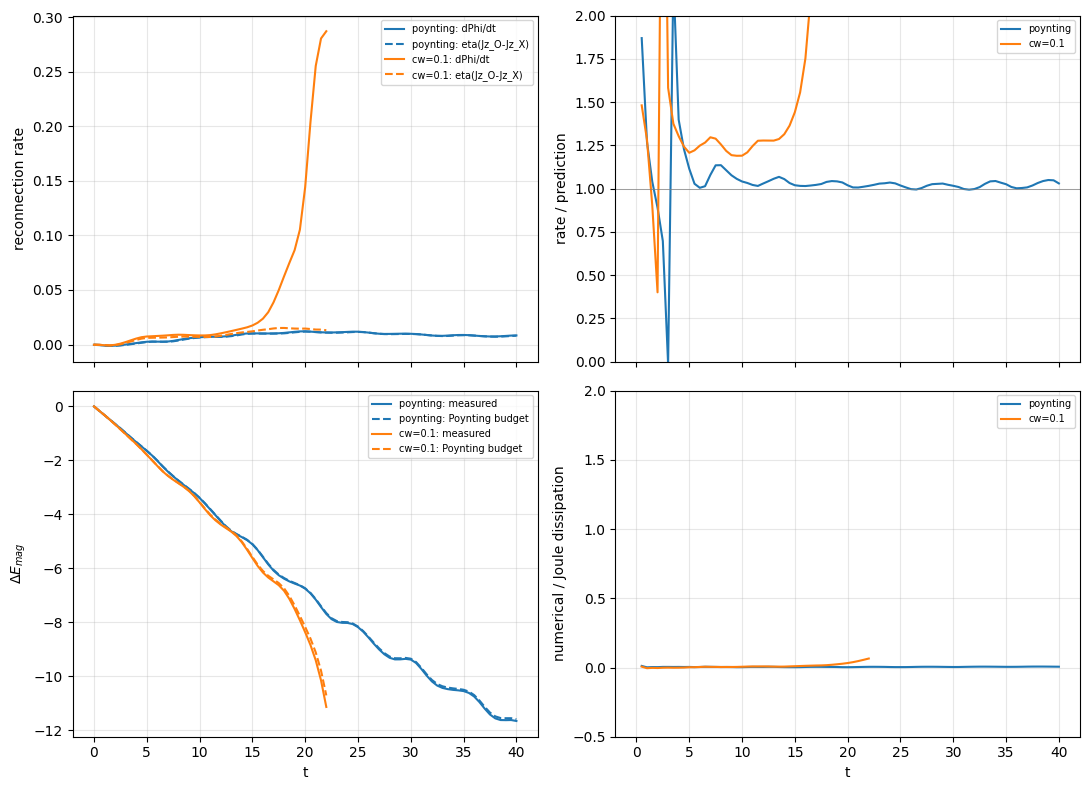

In [21]:
"""
theory_checks.py -- two checks against exact relations, for d_i = 0 runs

CHECK 1 (X-point identity).  With psi_hat(x) = integral of By dx along the midplane,
  Faraday gives d(psi_hat)/dt = Ez + c(t).  At the X- and O-points B = 0, so the
  v x B term vanishes and Ez = eta*Jz there.  Phi = psi_hat(O) - psi_hat(X), hence
        dPhi/dt = eta * ( Jz(O) - Jz(X) )         (exact, resistive MHD, d_i = 0)

CHECK 2 (magnetic energy budget, Poynting's theorem; mu0 = 1).
        dE_mag/dt = - Int( eta J^2 + v.(J x B) ) dA  -  (wall Poynting flux)
  The residual is the numerical dissipation of B. Its size relative to the
  physical Joule heating Int( eta J^2 ) dt says whether eta or the grid sets the
  dissipation.
"""
import os, glob
import numpy as np
import matplotlib.pyplot as plt

BASE = os.path.expanduser('~/Research/runs')
RUNS = {
    # 'old':         'gem/di_0_res1',
    'poynting':    'gem/di_0.0_rk3_poynting',
    # 'no poynting': 'gem/di_0.0_rk3_nopoynting',
    'cw=0.1': 'gem/di_1.0_rk3_poynting_cw0.1'
}
P, DT_OUT, T_FINAL = 10, 0.5, 40.0
ETA = 0.005
VEL_IS_MOMENTUM = False     # True if u1,u2,u3 are rho*v rather than v
T_FIT = 10.0                # skip the initial transient when averaging errors


def load(run_dir, name, n):
    return np.vstack([np.loadtxt(f'{run_dir}/{name}_files/{name}_p{p:03d}_{n:03d}')
                      for p in range(P)])


def cumtrapz(f, t):
    return np.concatenate([[0.0], np.cumsum(0.5*(f[1:] + f[:-1])*np.diff(t))])


def analyze(run_dir):
    y = np.loadtxt(f'{run_dir}/mesh_files/y')
    x = np.concatenate([np.loadtxt(f'{run_dir}/mesh_files/x_p{p:03d}') for p in range(P)])
    dx, dy = np.gradient(x).mean(), np.gradient(y).mean()
    dA = dx*dy
    k0 = np.searchsorted(y, 0.0) - 1                 # rows k0, k0+1 straddle y = 0
    mid = lambda a: 0.5*(a[:, k0] + a[:, k0+1])
    N = len(glob.glob(f'{run_dir}/b2_files/b2_p000_*'))

    keys = ['t', 'Phi', 'JzX', 'JzO', 'BX', 'BO', 'QJ', 'WL', 'Fw', 'Emag']
    d = {k: [] for k in keys}
    for n in range(N):
        tn = n*DT_OUT
        if tn > T_FINAL + 1e-9:
            break
        Bx, By, Bz = (load(run_dir, b, n) for b in ('b1', 'b2', 'b3'))
        vx, vy, vz = (load(run_dir, u, n) for u in ('u1', 'u2', 'u3'))
        if VEL_IS_MOMENTUM:
            rho = load(run_dir, 'rho', n)
            vx, vy, vz = vx/rho, vy/rho, vz/rho

        Jx = np.gradient(Bz, y, axis=1)
        Jy = -np.gradient(Bz, x, axis=0)
        Jz = np.gradient(By, x, axis=0) - np.gradient(Bx, y, axis=1)

        # ---- check 1: X- and O-points from psi_hat along the midplane
        by = mid(By)
        psi = np.concatenate([[0.0], np.cumsum(0.5*(by[1:] + by[:-1])*np.diff(x))])
        iO, iX = np.argmax(psi), np.argmin(psi)
        jz = mid(Jz)
        bmag = np.hypot(mid(Bx), by)
        d['Phi'].append(psi[iO] - psi[iX])
        d['JzX'].append(jz[iX]); d['JzO'].append(jz[iO])
        d['BX'].append(bmag[iX]); d['BO'].append(bmag[iO])

        # ---- check 2: budget terms
        d['QJ'].append(ETA*(Jx**2 + Jy**2 + Jz**2).sum()*dA)
        d['WL'].append((vx*(Jy*Bz - Jz*By) + vy*(Jz*Bx - Jx*Bz)
                        + vz*(Jx*By - Jy*Bx)).sum()*dA)
        Ez = -(vx*By - vy*Bx) + ETA*Jz
        Ex = -(vy*Bz - vz*By) + ETA*Jx
        Sy = Ez*Bx - Ex*Bz                              # y-component of E x B
        d['Fw'].append((Sy[:, -1].sum() - Sy[:, 0].sum())*dx)   # outward flux, both walls
        d['Emag'].append(0.5*(Bx**2 + By**2 + Bz**2).sum()*dA)
        d['t'].append(tn)

    d = {k: np.array(v) for k, v in d.items()}
    t = d['t']
    d['rate'] = np.gradient(d['Phi'], t)
    d['pred'] = ETA*(d['JzO'] - d['JzX'])
    d['dEmag'] = d['Emag'] - d['Emag'][0]
    d['budget'] = -cumtrapz(d['QJ'] + d['WL'] + d['Fw'], t)    # predicted dE_mag
    d['Dnum'] = -(d['dEmag'] - d['budget'])                    # extra loss beyond physics
    d['Jtot'] = cumtrapz(d['QJ'], t)
    print(f'{run_dir}: {len(t)} outputs')
    return d


res = {}
for label, folder in RUNS.items():
    p = os.path.join(BASE, folder)
    if os.path.isdir(p):
        res[label] = analyze(p)
    else:
        print(f'skipping {label}: {p} not found')

# ---- tables
for label, d in res.items():
    t = d['t']; m = t >= T_FIT
    err = np.abs(d['rate'][m] - d['pred'][m]) / np.abs(d['pred'][m])
    print(f'\n=== {label} ===')
    print('CHECK 1  rate = dPhi/dt vs eta*(Jz(O)-Jz(X));  mean |rel err| for t>=%g: %.1f%%  (max %.1f%%)'
          % (T_FIT, 100*err.mean(), 100*err.max()))
    print('   max |B| at the X/O points (should be ~0): X %.2e   O %.2e'
          % (d['BX'].max(), d['BO'].max()))
    print('CHECK 2  numerical dissipation of B / physical Joule heating:')
    print(f"   {'t':>5s} {'rate':>9s} {'pred':>9s} {'ratio':>7s} {'Dnum':>9s} {'Joule':>9s} {'Dnum/J':>7s}")
    for tt in (10, 20, 30, 40):
        i = np.argmin(np.abs(t - tt))
        print(f"   {t[i]:5.1f} {d['rate'][i]:9.5f} {d['pred'][i]:9.5f} "
              f"{d['rate'][i]/d['pred'][i]:7.2f} {d['Dnum'][i]:9.4f} "
              f"{d['Jtot'][i]:9.4f} {d['Dnum'][i]/d['Jtot'][i]:7.2f}")

# ---- plots
fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for label, d in res.items():
    t = d['t']
    ln, = axs[0, 0].plot(t, d['rate'], label=f'{label}: dPhi/dt')
    axs[0, 0].plot(t, d['pred'], '--', color=ln.get_color(), label=f'{label}: eta(Jz_O-Jz_X)')
    axs[0, 1].plot(t[1:], d['rate'][1:]/d['pred'][1:], label=label)
    axs[1, 0].plot(t, d['dEmag'], color=ln.get_color(), label=f'{label}: measured')
    axs[1, 0].plot(t, d['budget'], '--', color=ln.get_color(), label=f'{label}: Poynting budget')
    axs[1, 1].plot(t[1:], d['Dnum'][1:]/d['Jtot'][1:], label=label)
axs[0, 0].set_ylabel('reconnection rate'); axs[0, 1].set_ylabel('rate / prediction')
axs[0, 1].axhline(1, color='gray', lw=0.5); axs[0, 1].set_ylim(0, 2)
axs[1, 0].set_ylabel(r'$\Delta E_{mag}$'); axs[1, 1].set_ylabel('numerical / Joule dissipation')
axs[1, 1].set_ylim(-0.5, 2)
for a in axs.flat:
    a.grid(alpha=0.3); a.legend(fontsize=7)
for a in axs[1]:
    a.set_xlabel('t')
fig.tight_layout()
fig.savefig(os.path.join(BASE, 'theory_checks.png'), dpi=150)
plt.show()

In [24]:
import numpy as np, os
RUN = os.path.expanduser('~/Research/runs/gem/di_1.0_rk3_poynting_cw0.1')
# RUN = os.path.expanduser('~/Research/runs/gem/di_0.0_rk3_poynting')
P, DT = 10, 0.5
y = np.loadtxt(f'{RUN}/mesh_files/y')
x = np.concatenate([np.loadtxt(f'{RUN}/mesh_files/x_p{p:03d}') for p in range(P)])
load = lambda nm, n: np.vstack([np.loadtxt(f'{RUN}/{nm}_files/{nm}_p{p:03d}_{n:03d}') for p in range(P)])

def checker(a):
    """grid-scale (odd-even) noise: |a - neighbour average| / |a|, max over the domain"""
    dx = np.abs(a[1:-1, :] - 0.5*(a[2:, :] + a[:-2, :])) / np.abs(a[1:-1, :])
    dy = np.abs(a[:, 1:-1] - 0.5*(a[:, 2:] + a[:, :-2])) / np.abs(a[:, 1:-1])
    return max(dx.max(), dy.max())

print(f"{'t':>5} {'min rho':>8} {'at (x,y)':>14} {'min p':>8} {'at (x,y)':>14} {'chk rho':>8} {'chk p':>8}")
for n in range(0, 45):                      # t = 15 .. 22.5
    try:
        rho, p = load('rho', n), load('p', n)
    except OSError:
        break
    i = np.unravel_index(rho.argmin(), rho.shape); j = np.unravel_index(p.argmin(), p.shape)
    print(f"{n*DT:5.1f} {rho.min():8.4f} ({x[i[0]]:5.1f},{y[i[1]]:5.1f}) "
          f"{p.min():8.4f} ({x[j[0]]:5.1f},{y[j[1]]:5.1f}) {checker(rho):8.3f} {checker(p):8.3f}")

def checker_abs(a):
    s = np.abs(a).max()
    dx = np.abs(a[1:-1, :] - 0.5*(a[2:, :] + a[:-2, :])).max()
    dy = np.abs(a[:, 1:-1] - 0.5*(a[:, 2:] + a[:, :-2])).max()
    return max(dx, dy) / s

GAMMA = 5/3
print(f"\n{'t':>5} {'chk Bz':>8} {'chk B^2':>8} {'chk U':>8}")
for n in range(0, 45):
    try:
        B = [load(b, n) for b in ('b1', 'b2', 'b3')]
        rho, p = load('rho', n), load('p', n)
        v = [load(u, n) for u in ('u1', 'u2', 'u3')]
    except OSError:
        break
    B2 = sum(b**2 for b in B)
    U = p/(GAMMA-1) + 0.5*rho*sum(vi**2 for vi in v) + 0.5*B2
    print(f"{n*DT:5.1f} {checker_abs(B[2]):8.3f} {checker_abs(B2):8.3f} {checker_abs(U):8.3f}")

    t  min rho       at (x,y)    min p       at (x,y)  chk rho    chk p
  0.0   0.2000 (-12.8, -6.4)   0.1000 (-12.4, -6.4)    0.013    0.013
  0.5   0.1996 ( 12.6,  6.4)   0.0997 ( 12.8,  5.9)    0.015    0.013
  1.0   0.1984 (-12.6,  6.4)   0.0986 (-11.5,  4.3)    0.015    0.013
  1.5   0.1944 (-12.3,  4.3)   0.0867 (-11.6,  5.2)    0.040    0.260
  2.0   0.1771 (-12.1,  4.3)   0.0936 (-11.9,  4.3)    0.238    0.103
  2.5   0.1701 (-11.9,  4.2)   0.0954 (-12.1,  1.7)    0.337    0.046
  3.0   0.1830 (-11.8,  4.3)   0.0933 (-12.8, -1.8)    0.183    0.015
  3.5   0.1647 (-11.8,  4.3)   0.0922 (-12.8,  2.0)    0.424    0.015
  4.0   0.1738 (-11.7,  4.3)   0.0924 (-12.8,  2.1)    0.314    0.016
  4.5   0.1836 (-11.7,  4.3)   0.0934 (-12.7,  2.3)    0.199    0.018
  5.0   0.1713 (-11.7,  4.3)   0.0949 ( 12.4,  2.5)    0.351    0.020
  5.5   0.1797 (-11.7,  4.3)   0.0961 (-11.7,  2.8)    0.241    0.020
  6.0   0.1805 (-11.7,  4.2)   0.0966 (-12.1,  3.1)    0.217    0.019
  6.5   0.1654 (-1

/var/folders/x3/qnpsvxcs5c7449x05517mcz80000gn/T/ipykernel_88649/2244951453.py:29: RuntimeWarning: invalid value encountered in scalar divide
  return max(dx, dy) / s


  0.0      nan    0.015    0.005
  0.5    0.065    0.015    0.005
  1.0    0.026    0.014    0.005
  1.5    0.027    0.014    0.035
  2.0    0.027    0.013    0.015
  2.5    0.029    0.012    0.007
  3.0    0.039    0.014    0.004
  3.5    0.078    0.016    0.004
  4.0    0.183    0.018    0.005
  4.5    0.290    0.020    0.006
  5.0    0.387    0.020    0.006
  5.5    0.475    0.020    0.006
  6.0    0.553    0.019    0.005
  6.5    0.647    0.018    0.005
  7.0    0.766    0.018    0.004
  7.5    0.898    0.018    0.005
  8.0    0.779    0.018    0.005
  8.5    0.677    0.018    0.005
  9.0    0.591    0.017    0.005
  9.5    0.546    0.017    0.005
 10.0    0.550    0.016    0.004
 10.5    0.606    0.016    0.004
 11.0    0.727    0.016    0.004
 11.5    0.761    0.016    0.004
 12.0    0.734    0.017    0.005
 12.5    0.656    0.019    0.005
 13.0    0.554    0.020    0.006
 13.5    0.490    0.022    0.006
 14.0    0.462    0.023    0.006
 14.5    0.462    0.024    0.006
 15.0    0